# Benchmark: StarSim v4 (inverse-model branch) vs StarSim (D. Baroch), `fast` mode — time and RAM

The two older codes compared with each other, in **photometry** (light curve) and in **RV mode** (CCF, RV, FWHM, BIS, contrast):

| | StarSim v4 | StarSim (D. Baroch), `fast` mode |
|---|---|---|
| code | branch `inverse-model` (path `starsim4` of `local_paths.ini`) | path `starsim_david` of `local_paths.ini`, `simulation_mode = fast` |
| method | grid of cells (`n_ring` rings): the flux / CCF of every cell, the cells touched by a region changed at every epoch | loop over the **regions** instead of the cells of the grid: the effect of every spot and facula is computed from the rings it covers (its code says it only works for regions that do not overlap) |
| one simulation | `StarSim(conf)` then `simulate_forward(times, observables)` | `StarSim(conf)` then `compute_forward(observables, t)` |

**Same measurement as the two benchmarks.** The probe (time and RSS of every step), the runners (one run = one new Python process) and the `run` functions are those of `benchmark_starsim4.ipynb` and `benchmark_starsim_david.ipynb`: they are read from these notebooks and executed here, each in its own namespace (`v4`, `dav`), so the measurements are exactly those of the two benchmarks. Both codes run with the Python of the environment `sunsim` (Python 3.14, NumPy 2.4, Numba 0.65), with their Numba caches in the temporary folders of the benchmarks (written by the warm-ups, not measured).

**Same inputs.** The star, the regions and the cases of the two benchmarks, which are the same: T_eff = 5800 K, log g = 4.5, spot ΔT = 500 K, facula ΔT = 30 K, Q = 3 (a facula of radius r√(1 + Q) around every spot), P = 25.05 d, equator-on; Phoenix SPECINT (photometry, brightness of the rings) and HiRes (CCFs) models of `models` of the old StarSim; filter `TJO_R.dat` (3700–9500 Å); velocity grid ±18 km/s by 0.25 km/s. The CCF mask is the same for both: `HARPS_G20_mps_friendly.mas` (the mask of the StarSim v4 benchmark, copied into the work copy of StarSim (D. Baroch)). Regions: the reference spot of 8° (facula of 16°) on the equator, plus spots of 2–6° at random positions (fixed seed) for `n_regions = 10, 30`.

**Same statistics for both.** Every case in `n_processes` new processes (import, first run, new session = import + first run: medians over the processes); in every process the simulation is repeated (`n_next` times, at least `min_next`, and no more once the repetitions took `max_warm_seconds`): the **next runs** are the median of all of them. The two codes alternate in every case.

**What is not compared here.** The outputs: the `fast` mode is not exact (section 9 of `benchmark_starsim_david.ipynb`: 5e-4 in flux and ~0.3 m/s in RV from its own `grid` mode with a spot and its facula, whatever the number of rings), and with 10 or 30 random spots the regions may overlap, which the `fast` mode does not handle. StarSim v4 and StarSim (D. Baroch) also differ in their CCF measurement and in details of the spectra (see the two benchmarks). Only time and RAM are compared.

**Running time.** About 1 hour (most of it for StarSim v4 at 200 and 500 rings and with 5000 epochs in RV).

## 1. Set-up: the two benchmarks, each in its own namespace

In [1]:
import os, json, shutil, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

HERE = os.getcwd()                               # the folder of the notebooks


def code_cells(name):
    """Source of the code cells of a notebook of this folder."""
    nb = json.load(open(os.path.join(HERE, name)))
    return [''.join(c['source']) for c in nb['cells'] if c['cell_type'] == 'code']


def load_benchmark(name, starts, before_run=None):
    """Executes the cells of `name` that start with one of `starts` (in this order) in a new namespace; the
    `%%writefile {var}` cells are written to the path of `var`. before_run(ns) is called before the cell `def run(`
    (whose warm-up runs the codes)."""
    ns = {'__name__': name}
    cells = code_cells(name)
    for start in starts:
        src = [c for c in cells if c.startswith(start)]
        assert len(src) == 1, (name, start)
        src = src[0]
        if src.startswith('%%writefile'):
            first, body = src.split('\n', 1)
            with open(ns[first.split('{')[1].split('}')[0]], 'w') as f:
                f.write(body)
            continue
        if start.startswith('def run(') and before_run is not None:
            before_run(ns)
        exec(src, ns)
    return ns


common = ['import os, sys, json, time', '%%writefile {probe_path}']
v4 = load_benchmark('benchmark_starsim4.ipynb', common + ['%%writefile {runner_v4}', '%%writefile {runner_opt}', 'def run('])


def same_mask(ns):
    """StarSim (D. Baroch) with the mask of the StarSim v4 benchmark (copied into its work copy, where it reads its masks)."""
    shutil.copy(v4['star']['mask'], os.path.join(ns['david_work'], 'starsim', 'masks'))
    ns['star']['mask'] = os.path.basename(v4['star']['mask'])


dav = load_benchmark('benchmark_starsim_david.ipynb', common + ['%%writefile {runner_david}', '%%writefile {runner_sunsim}', 'def run('],
                     before_run=same_mask)

# the same statistics and cases for both
n_processes = 3
for ns in (v4, dav):
    ns['n_next'], ns['min_next'], ns['max_warm_seconds'] = 10, 3, 10.0
reference = {'n_rings': 50, 'n_epochs': 100, 'n_regions': 1}
sweeps = {'n_rings': [10, 20, 50, 100, 200, 500], 'n_epochs': [100, 1000, 5000], 'n_regions': [1, 10, 30]}
modes = ['phot', 'rv']
mode_names = {'phot': 'photometry', 'rv': 'RV'}
codes = ['StarSim v4', 'David fast']
assert v4['reference'] == dav['reference'] == reference and v4['sweeps'] == dav['sweeps'] == sweeps
assert v4['make_regions'](30) == dav['make_regions'](30)
for k in ('T_eff', 'dT_spot', 'dT_fac', 'logg', 'radius', 'P_rot', 'inclination', 'Q', 'band', 'filter', 'rv_range', 'rv_step'):
    assert v4['star'][k] == dav['star'][k], k
print('work folders:', v4['work_dir'], dav['work_dir'])

machine: macOS-26.6.2-arm64-arm-64bit, 10 CPUs
temporary folder (scripts, configuration files, outputs): /var/folders/zk/_1ntmgv17vb6c_z2qnyqyytc0000gn/T/benchmark_starsim4_mpydd0qm


python 3.14.5 | numpy 2.4.6 | numba 0.65.1 (10 threads) | scipy 1.17.1 | astropy 7.2.0
machine: macOS-26.6.2-arm64-arm-64bit, 10 CPUs
work folder (copy of StarSim (D. Baroch), scripts, configuration files, outputs): /var/folders/zk/_1ntmgv17vb6c_z2qnyqyytc0000gn/T/benchmark_starsim_david_4d3bbveo


python 3.14.5 | numpy 2.4.6 | numba 0.65.1 (10 threads) | scipy 1.17.1 | astropy 7.2.0


bisectors, max |StarSim (D. Baroch) - SunSim| [km/s]: CIFIST 0.0, Dumusque 0.0
work folders: /var/folders/zk/_1ntmgv17vb6c_z2qnyqyytc0000gn/T/benchmark_starsim4_mpydd0qm /var/folders/zk/_1ntmgv17vb6c_z2qnyqyytc0000gn/T/benchmark_starsim_david_4d3bbveo


## 2. Runs

Every case of `sweeps` (the reference once), for the two modes and the two codes, in `n_processes` new processes each; the processes are interleaved (all the cases, then all the cases again) and the order of the two codes alternates.

In [2]:
cases = []
for key, values in sweeps.items():
    for v in values:
        case = dict(reference, **{key: v})
        if case not in cases:
            cases.append(case)


def run(code, mode, case, process):
    if code == 'StarSim v4':
        r = v4['run']('StarSim v4', mode, case, process=200 + process)
    else:
        r = dav['run']('David', mode, case, process=200 + process, tag='_fast', simulation_mode='fast')
    r['code'] = code
    return r


runs = []
t_start = time.perf_counter()
for process in range(n_processes):
    t0 = time.perf_counter()
    for i, case in enumerate(cases):
        for mode in modes:
            for code in (codes if (process + i) % 2 == 0 else codes[::-1]):
                runs.append(run(code, mode, case, process))
    print('processes %d/%d done (%.1f min)' % (process + 1, n_processes, (time.perf_counter() - t0) / 60))
print('%d runs in %.1f min' % (len(runs), (time.perf_counter() - t_start) / 60))

processes 1/3 done (6.1 min)


processes 2/3 done (5.6 min)


processes 3/3 done (5.5 min)
120 runs in 17.3 min


## 3. Time and RAM

For every process: import, first run (`init` + first `simulate_forward` / `compute_forward`), new session = import + first run, the next runs, the RAM after the import, the peak RAM of the process and the RAM used by the simulations (peak − after import). Medians over the processes (over all the repetitions for the next runs).

In [3]:
def per_process(r):
    st = {s['step']: s for s in r['steps']}
    forward = [s for s in r['steps'] if s['step'].startswith(('simulate_forward', 'compute_forward'))]
    first = st['init']['time [s]'] + forward[0]['time [s]']
    return {'code': r['code'], 'mode': r['mode'], 'n_rings': r['n_rings'], 'n_epochs': r['n_epochs'], 'n_regions': r['n_regions'],
            'import [s]': st['import']['time [s]'], 'first run [s]': first, 'new session [s]': st['import']['time [s]'] + first,
            'next': [s['time [s]'] for s in forward[1:]],
            'RAM after import [MB]': st['import']['rss after [MB]'], 'RAM peak [MB]': r['rss max process [MB]'],
            'RAM for the simulations [MB]': r['rss max process [MB]'] - st['import']['rss after [MB]']}


keys = ['code', 'mode', 'n_rings', 'n_epochs', 'n_regions']
cold = ['import [s]', 'first run [s]', 'new session [s]', 'RAM after import [MB]', 'RAM peak [MB]', 'RAM for the simulations [MB]']
processes = pd.DataFrame([per_process(r) for r in runs])


def aggregate(g):
    out = {c: np.median(g[c]) for c in cold}
    nxt = np.concatenate(g['next'].to_list())
    out['next runs [s]'] = np.median(nxt)
    out['q25 next runs [s]'], out['q75 next runs [s]'] = np.percentile(nxt, [25, 75])
    out['q25 new session [s]'], out['q75 new session [s]'] = np.percentile(g['new session [s]'], [25, 75])
    return pd.Series(out)


summary = processes.groupby(keys, sort=False)[cold + ['next']].apply(aggregate).reset_index()


def sweep_rows(mode, key, code):
    others = [k for k in reference if k != key]
    d = summary[(summary['mode'] == mode) & (summary.code == code)
                & np.logical_and.reduce([summary[k] == reference[k] for k in others])]
    return d.sort_values(key).set_index(key)


columns = ['new session [s]', 'next runs [s]', 'RAM peak [MB]', 'RAM for the simulations [MB]']
pd.options.display.float_format = '{:.3g}'.format
for mode in modes:
    for key in sweeps:
        a, b = sweep_rows(mode, key, 'StarSim v4'), sweep_rows(mode, key, 'David fast')
        t = pd.concat({'StarSim v4': a[columns], 'David fast': b[columns]}, axis=1)
        t[('v4 / fast', 'new session')] = a['new session [s]'] / b['new session [s]']
        t[('v4 / fast', 'next runs')] = a['next runs [s]'] / b['next runs [s]']
        t[('v4 − fast', 'RAM peak [MB]')] = a['RAM peak [MB]'] - b['RAM peak [MB]']
        print('\n%s, %s (other parameters: %s)' % (mode_names[mode].upper(), key,
              ', '.join('%s = %d' % (k, v) for k, v in reference.items() if k != key)))
        display(t)


PHOTOMETRY, n_rings (other parameters: n_epochs = 100, n_regions = 1)


StarSim v4                              \
        new session [s] next runs [s] RAM peak [MB]   
n_rings                                               
10                 1.43       0.00863           388   
20                 1.22        0.0103           358   
50                  1.3        0.0284           392   
100                1.74        0.0869           396   
200                1.64         0.334           425   
500                3.51             2           495   

                                          David fast                \
        RAM for the simulations [MB] new session [s] next runs [s]   
n_rings                                                              
10                               177            1.58        0.0275   
20                               147            1.52        0.0246   
50                               180            1.67        0.0279   
100                              188            1.56         0.031   
200                              212            1.73        0.0436   
500                              283            1.94        0.0936   

                                                     v4 / fast            \
        RAM peak [MB] RAM for the simulations [MB] new session next runs   
n_rings                                                                    
10                312                         93.6       0.902     0.314   
20                293                         75.7       0.805      0.42   
50                315                          100       0.778      1.02   
100               306                         88.8        1.12       2.8   
200               330                          113       0.949      7.67   
500               487                          270        1.81      21.4   

            v4 − fast  
        RAM peak [MB]  
n_rings                
10               76.7  
20               65.6  
50                 77  
100              90.3  
200              95.4  
500              7.37


PHOTOMETRY, n_epochs (other parameters: n_rings = 50, n_regions = 1)


StarSim v4                              \
         new session [s] next runs [s] RAM peak [MB]   
n_epochs                                               
100                  1.3        0.0284           392   
1000                 1.6         0.198           417   
5000                2.25         0.954           429   

                                           David fast                \
         RAM for the simulations [MB] new session [s] next runs [s]   
n_epochs                                                              
100                               180            1.67        0.0279   
1000                              204            1.73         0.069   
5000                              215            1.74         0.265   

                                                      v4 / fast            \
         RAM peak [MB] RAM for the simulations [MB] new session next runs   
n_epochs                                                                    
100                315                          100       0.778      1.02   
1000               309                         91.5       0.928      2.87   
5000               320                          103        1.29       3.6   

             v4 − fast  
         RAM peak [MB]  
n_epochs                
100                 77  
1000               107  
5000               109


PHOTOMETRY, n_regions (other parameters: n_rings = 50, n_epochs = 100)


...

StarSim v4                              \
        new session [s] next runs [s] RAM peak [MB]   
n_rings                                               
10                 1.56         0.281           469   
20                 1.57         0.294           492   
50                  1.7         0.374           542   
100                 2.1         0.656           633   
200                3.28          1.72       1.2e+03   
500                11.5          10.5      4.72e+03   

                                          David fast                \
        RAM for the simulations [MB] new session [s] next runs [s]   
n_rings                                                              
10                               258            1.88         0.344   
20                               280            1.86         0.349   
50                               331            2.04         0.366   
100                              421            2.24         0.406   
200                              987             2.2         0.475   
500                         4.51e+03            2.83          1.18   

                                                     v4 / fast            \
        RAM peak [MB] RAM for the simulations [MB] new session next runs   
n_rings                                                                    
10                438                          221       0.829     0.818   
20                442                          226       0.845     0.843   
50                448                          231       0.834      1.02   
100               461                          245       0.938      1.62   
200               561                          342        1.49      3.62   
500          1.35e+03                     1.13e+03        4.07      8.93   

            v4 − fast  
        RAM peak [MB]  
n_rings                
10               31.9  
20               49.4  
50               93.7  
100               171  
200               637  
500          3.38e+03


RV, n_epochs (other parameters: n_rings = 50, n_regions = 1)


StarSim v4                              \
         new session [s] next runs [s] RAM peak [MB]   
n_epochs                                               
100                  1.7         0.374           542   
1000                4.05          2.77           508   
5000                14.7          13.5           490   

                                           David fast                \
         RAM for the simulations [MB] new session [s] next runs [s]   
n_epochs                                                              
100                               331            2.04         0.366   
1000                              296            2.09         0.581   
5000                              279             3.2          1.64   

                                                      v4 / fast            \
         RAM peak [MB] RAM for the simulations [MB] new session next runs   
n_epochs                                                                    
100                448                          231       0.834      1.02   
1000               436                          221        1.94      4.77   
5000               452                          236        4.59      8.18   

             v4 − fast  
         RAM peak [MB]  
n_epochs                
100               93.7  
1000              71.6  
5000              38.3


RV, n_regions (other parameters: n_rings = 50, n_epochs = 100)


StarSim v4                              \
          new session [s] next runs [s] RAM peak [MB]   
n_regions                                               
1                     1.7         0.374           542   
10                   1.91         0.469           519   
30                   1.91         0.529           545   

                                            David fast                \
          RAM for the simulations [MB] new session [s] next runs [s]   
n_regions                                                              
1                                  331            2.04         0.366   
10                                 307            2.15         0.423   
30                                 335            2.03         0.492   

                                                       v4 / fast            \
          RAM peak [MB] RAM for the simulations [MB] new session next runs   
n_regions                                                                    
1                   448                          231       0.834      1.02   
10                  479                          260       0.889      1.11   
30                  440                          223        0.94      1.07   

              v4 − fast  
          RAM peak [MB]  
n_regions                
1                  93.7  
10                   40  
30                  105

**Plots.** Time of one simulation (top: new session dashed, next runs solid, with the band between the 25th and 75th percentiles) and peak RAM of the process (bottom: solid; dotted: after the import), against every parameter, the others at the reference. Logarithmic axes for the time.

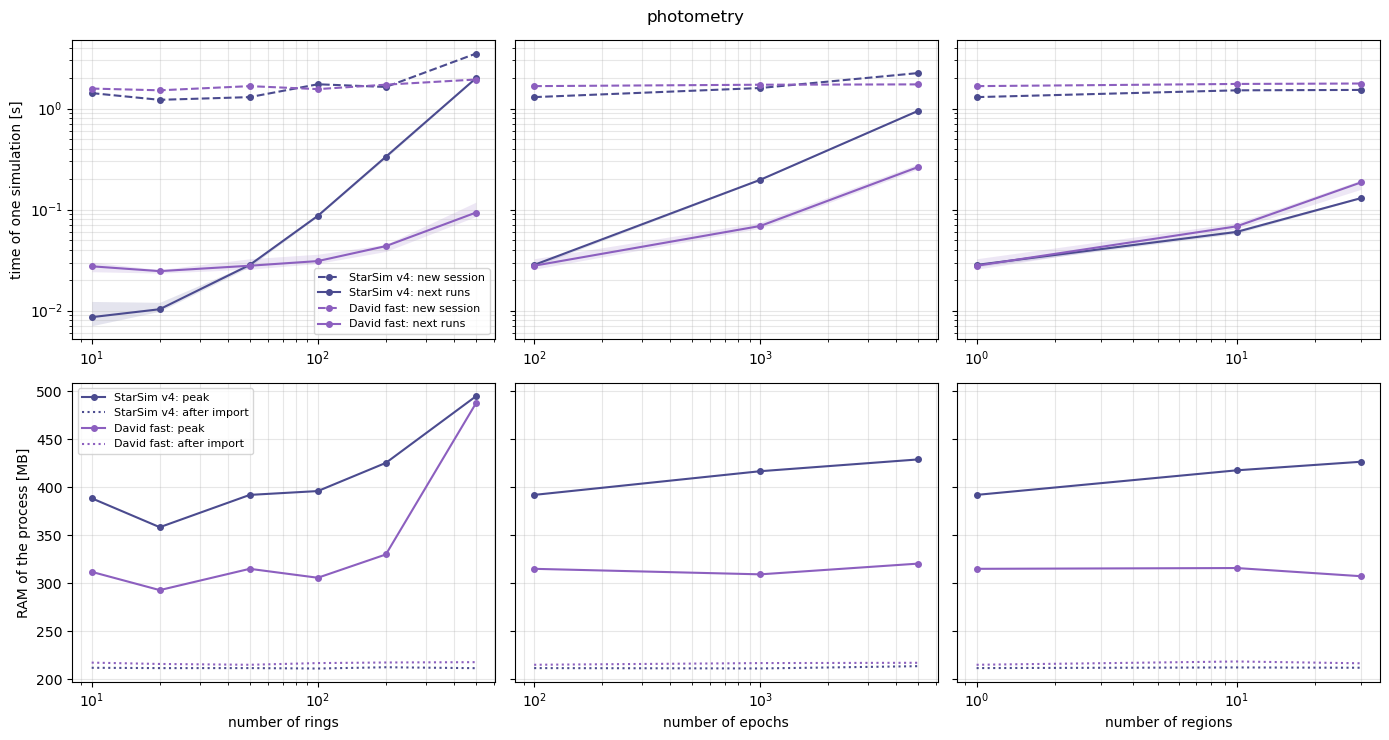

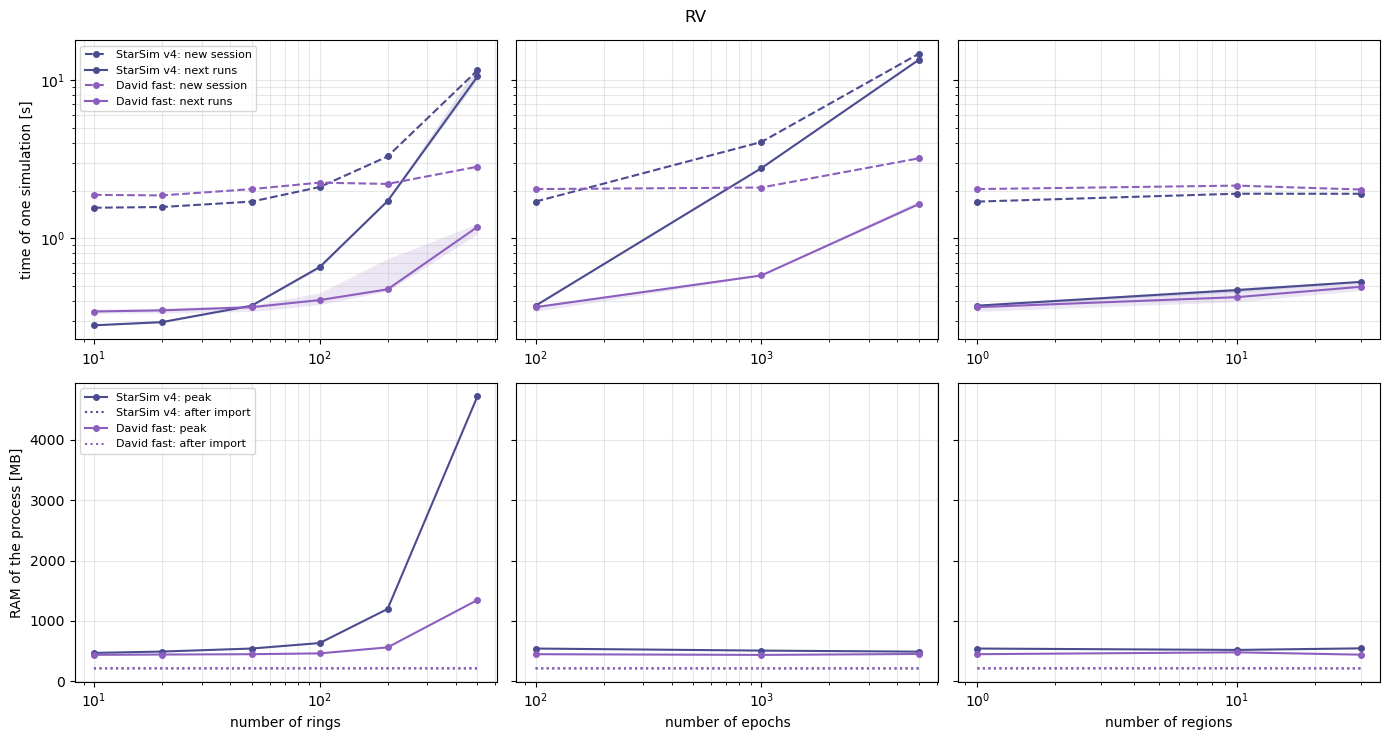

In [4]:
colors = {'StarSim v4': '#4b4b8f', 'David fast': '#8c5fbf'}
labels = {'n_rings': 'number of rings', 'n_epochs': 'number of epochs', 'n_regions': 'number of regions'}
for mode in modes:
    fig, axes = plt.subplots(2, 3, figsize=(14, 7.5), sharey='row')
    for j, key in enumerate(sweeps):
        for code in codes:
            d = sweep_rows(mode, key, code)
            x = d.index.values
            ax = axes[0, j]
            ax.plot(x, d['new session [s]'], '--o', color=colors[code], ms=4, label='%s: new session' % code)
            ax.plot(x, d['next runs [s]'], '-o', color=colors[code], ms=4, label='%s: next runs' % code)
            ax.fill_between(x, d['q25 next runs [s]'], d['q75 next runs [s]'], color=colors[code], alpha=0.15, lw=0)
            ax = axes[1, j]
            ax.plot(x, d['RAM peak [MB]'], '-o', color=colors[code], ms=4, label='%s: peak' % code)
            ax.plot(x, d['RAM after import [MB]'], ':', color=colors[code], label='%s: after import' % code)
        for i in (0, 1):
            axes[i, j].set_xscale('log')
            axes[i, j].grid(alpha=0.3, which='both')
        axes[0, j].set_yscale('log')
        axes[1, j].set_xlabel(labels[key])
    axes[0, 0].set_ylabel('time of one simulation [s]')
    axes[1, 0].set_ylabel('RAM of the process [MB]')
    axes[0, 0].legend(fontsize=8)
    axes[1, 0].legend(fontsize=8)
    fig.suptitle(mode_names[mode], fontsize=12)
    plt.tight_layout()
    plt.show()

## 4. Summary

The reference case and the range over all the cases of the sweeps: time of StarSim v4 / time of StarSim (D. Baroch) `fast` (> 1: the `fast` mode is faster), and peak RAM.

In [5]:
rows = []
for mode in modes:
    a = summary[(summary['mode'] == mode) & (summary.code == 'StarSim v4')].set_index(['n_rings', 'n_epochs', 'n_regions'])
    b = summary[(summary['mode'] == mode) & (summary.code == 'David fast')].set_index(['n_rings', 'n_epochs', 'n_regions'])
    ref = tuple(reference[k] for k in ['n_rings', 'n_epochs', 'n_regions'])
    for col in ['import [s]', 'new session [s]', 'next runs [s]', 'RAM after import [MB]', 'RAM peak [MB]', 'RAM for the simulations [MB]']:
        row = {'mode': mode_names[mode], 'quantity': col, 'StarSim v4 (reference)': a.loc[ref, col],
               'David fast (reference)': b.loc[ref, col],
               'StarSim v4 (all cases)': '%.3g–%.3g' % (a[col].min(), a[col].max()),
               'David fast (all cases)': '%.3g–%.3g' % (b[col].min(), b[col].max())}
        if col.endswith('[s]'):
            g = a[col] / b[col]
            row['v4 / fast (reference)'] = '%.2g' % g.loc[ref]
            row['v4 / fast (all cases)'] = '%.2g–%.2g' % (g.min(), g.max())
        else:
            d = a[col] - b[col]
            row['v4 / fast (reference)'] = '%+.0f MB' % d.loc[ref]
            row['v4 / fast (all cases)'] = '%+.0f to %+.0f MB' % (d.min(), d.max())
        rows.append(row)
pd.DataFrame(rows).set_index(['mode', 'quantity'])

StarSim v4 (reference)  \
mode       quantity                                               
photometry import [s]                                      1.22   
           new session [s]                                  1.3   
           next runs [s]                                 0.0284   
           RAM after import [MB]                            211   
           RAM peak [MB]                                    392   
           RAM for the simulations [MB]                     180   
RV         import [s]                                      1.22   
           new session [s]                                  1.7   
           next runs [s]                                  0.374   
           RAM after import [MB]                            211   
           RAM peak [MB]                                    542   
           RAM for the simulations [MB]                     331   

                                         David fast (reference)  \
mode       quantity                                               
photometry import [s]                                      1.61   
           new session [s]                                 1.67   
           next runs [s]                                 0.0279   
           RAM after import [MB]                            215   
           RAM peak [MB]                                    315   
           RAM for the simulations [MB]                     100   
RV         import [s]                                       1.6   
           new session [s]                                 2.04   
           next runs [s]                                  0.366   
           RAM after import [MB]                            217   
           RAM peak [MB]                                    448   
           RAM for the simulations [MB]                     231   

                                        StarSim v4 (all cases)  \
mode       quantity                                              
photometry import [s]                                 1.16–1.6   
           new session [s]                           1.22–3.51   
           next runs [s]                             0.00863–2   
           RAM after import [MB]                       211–213   
           RAM peak [MB]                               358–495   
           RAM for the simulations [MB]                147–283   
RV         import [s]                                1.16–1.38   
           new session [s]                           1.56–14.7   
           next runs [s]                            0.281–13.5   
           RAM after import [MB]                       211–213   
           RAM peak [MB]                          469–4.72e+03   
           RAM for the simulations [MB]           258–4.51e+03   

                                        David fast (all cases)  \
mode       quantity                                              
photometry import [s]                                 1.47–1.8   
           new session [s]                           1.52–1.94   
           next runs [s]                          0.0246–0.265   
           RAM after import [MB]                       215–218   
           RAM peak [MB]                               293–487   
           RAM for the simulations [MB]               75.7–270   
RV         import [s]                                1.46–1.71   
           new session [s]                            1.86–3.2   
           next runs [s]                            0.344–1.64   
           RAM after import [MB]                       216–218   
           RAM peak [MB]                          436–1.35e+03   
           RAM for the simulations [MB]           221–1.13e+03   

                                        v4 / fast (reference)  \
mode       quantity                                             
photometry import [s]                                    0.76   
           new session [s]                               0.78   
           next runs [s]                             

**Conclusions** (3 processes per case; reference case: 50 rings, 100 epochs, one spot + facula)

**Time.**
* *New session* (import + first run): StarSim (D. Baroch) imports more (emcee, corner, matplotlib, ...: 1.6 s against 1.2 s), so StarSim v4 starts faster in the small cases (1.3 s against 1.7 s in photometry, 1.7 s against 2.0 s in RV in the reference case). With large problems the `fast` mode wins: in RV 4× at 500 rings (2.8 s against 11.5 s) and 4.6× with 5000 epochs (3.2 s against 14.7 s); in photometry 1.8× at 500 rings.
* *Next runs, photometry*: the same in the reference case (28 ms for both). StarSim v4 is faster with a coarse grid (3× at 10 rings: 9 ms against 28 ms) and with many regions (30 regions: 0.13 s against 0.19 s, since the `fast` mode loops over the regions); the `fast` mode is faster with fine grids (2.8× at 100 rings, 7.7× at 200, 21× at 500: 0.09 s against 2.0 s) and with many epochs (3.6× with 5000 epochs).
* *Next runs, RV*: the same in the reference case (0.37 s for both) and up to 50 rings (StarSim v4 ~20 % faster at 10–20 rings); then the `fast` mode is faster: 1.6× at 100 rings, 3.6× at 200, 9× at 500 (1.2 s against 10.5 s), 4.8× with 1000 epochs and 8× with 5000 epochs (1.6 s against 13.5 s). The number of regions changes little in RV (1.0–1.1×).
* So the time of StarSim v4 grows with the number of cells (it handles every cell of the grid), that of the `fast` mode much less (it handles the rings covered by each region): the `fast` mode is not faster in the reference case, but it is for fine grids and long time series.

**RAM.**
* After the import: the same (211 MB for StarSim v4, 215–218 MB for StarSim (D. Baroch)).
* Peak: the `fast` mode needs less in every case: 77 MB less in photometry and 94 MB less in RV in the reference case. The gap grows with the grid in RV: StarSim v4 keeps the CCF of every cell for the three surfaces (1.2 GB at 200 rings, 4.7 GB at 500 rings), the `fast` mode 0.56 GB and 1.35 GB. In photometry the two are within 8 MB at 500 rings (~0.5 GB).

**Keep in mind.** The `fast` mode is an approximation (5e-4 in flux and ~0.3 m/s in RV from the exact `grid` mode of the same code, whatever the number of rings, `benchmark_starsim_david.ipynb` section 9), and it does not handle regions that overlap; StarSim v4 computes every cell. For the same simulations SunSim is faster than both in nearly every case (`benchmark_starsim4.ipynb`, `benchmark_starsim_david.ipynb`): next runs ~3× faster than either of them in photometry and ~12× in RV in the reference case. The exception is photometry at ≥ 200 rings, where the `fast` mode is faster than SunSim.

## 5. Clean up

In [6]:
for ns in (v4, dav):
    shutil.rmtree(ns['work_dir'], ignore_errors=True)
    print('deleted', ns['work_dir'])

deleted /var/folders/zk/_1ntmgv17vb6c_z2qnyqyytc0000gn/T/benchmark_starsim4_mpydd0qm


deleted /var/folders/zk/_1ntmgv17vb6c_z2qnyqyytc0000gn/T/benchmark_starsim_david_4d3bbveo
